In [76]:
import pandas as pd
from pandas.api.types import CategoricalDtype
from plotnine import *

# Global Data Pre-processing

In [96]:
mpc  = pd.read_csv('../saved_runs/data/mpc_results.csv')
mpc['type'] = 'MPC'
mpc.drop(columns='Unnamed: 0', inplace=True)

tmpc = pd.read_csv('../saved_runs/data/tmpc_results.csv')
tmpc['type'] = 'TMPC'
tmpc.drop(columns='Unnamed: 0', inplace=True)

data = pd.concat([mpc, tmpc])
data.reset_index(drop=True, inplace=True)

order = CategoricalDtype(
    categories=['MPC', 'TMPC'],
    ordered=True
)

def theme_poster(fig_size: tuple[int, int]): 
    return theme_tufte() + theme(
        figure_size=fig_size,
        text=element_text(colour='white'),
        
        legend_background=element_blank(),
        legend_position='right',
        
        panel_background=element_rect(fill='#0C2340', colour='#00000000'),
        plot_background=element_rect(fill='#0C2340', colour='#00000000'),
        strip_background=element_rect(fill='#0C2340', colour='#00000000'),

        panel_grid_major=element_blank(),
        panel_grid_minor=element_blank(),
    )

# Collisions
### Data Handling

In [78]:
collisions = data[['wall_collisions', 'victims_collisions', 'fire_collisions', 'type']]
collisions.columns = ['Terrain', 'Victim', 'Fire', 'type']
collisions = collisions.melt(id_vars='type', value_name='collisions', value_vars=['Terrain', 'Victim', 'Fire'], var_name='collision_type')
collisions['type'] = collisions['type'].astype(order)
collisions = collisions.value_counts(subset=['type', 'collisions', 'collision_type']).reset_index(name='count')

### Plotting

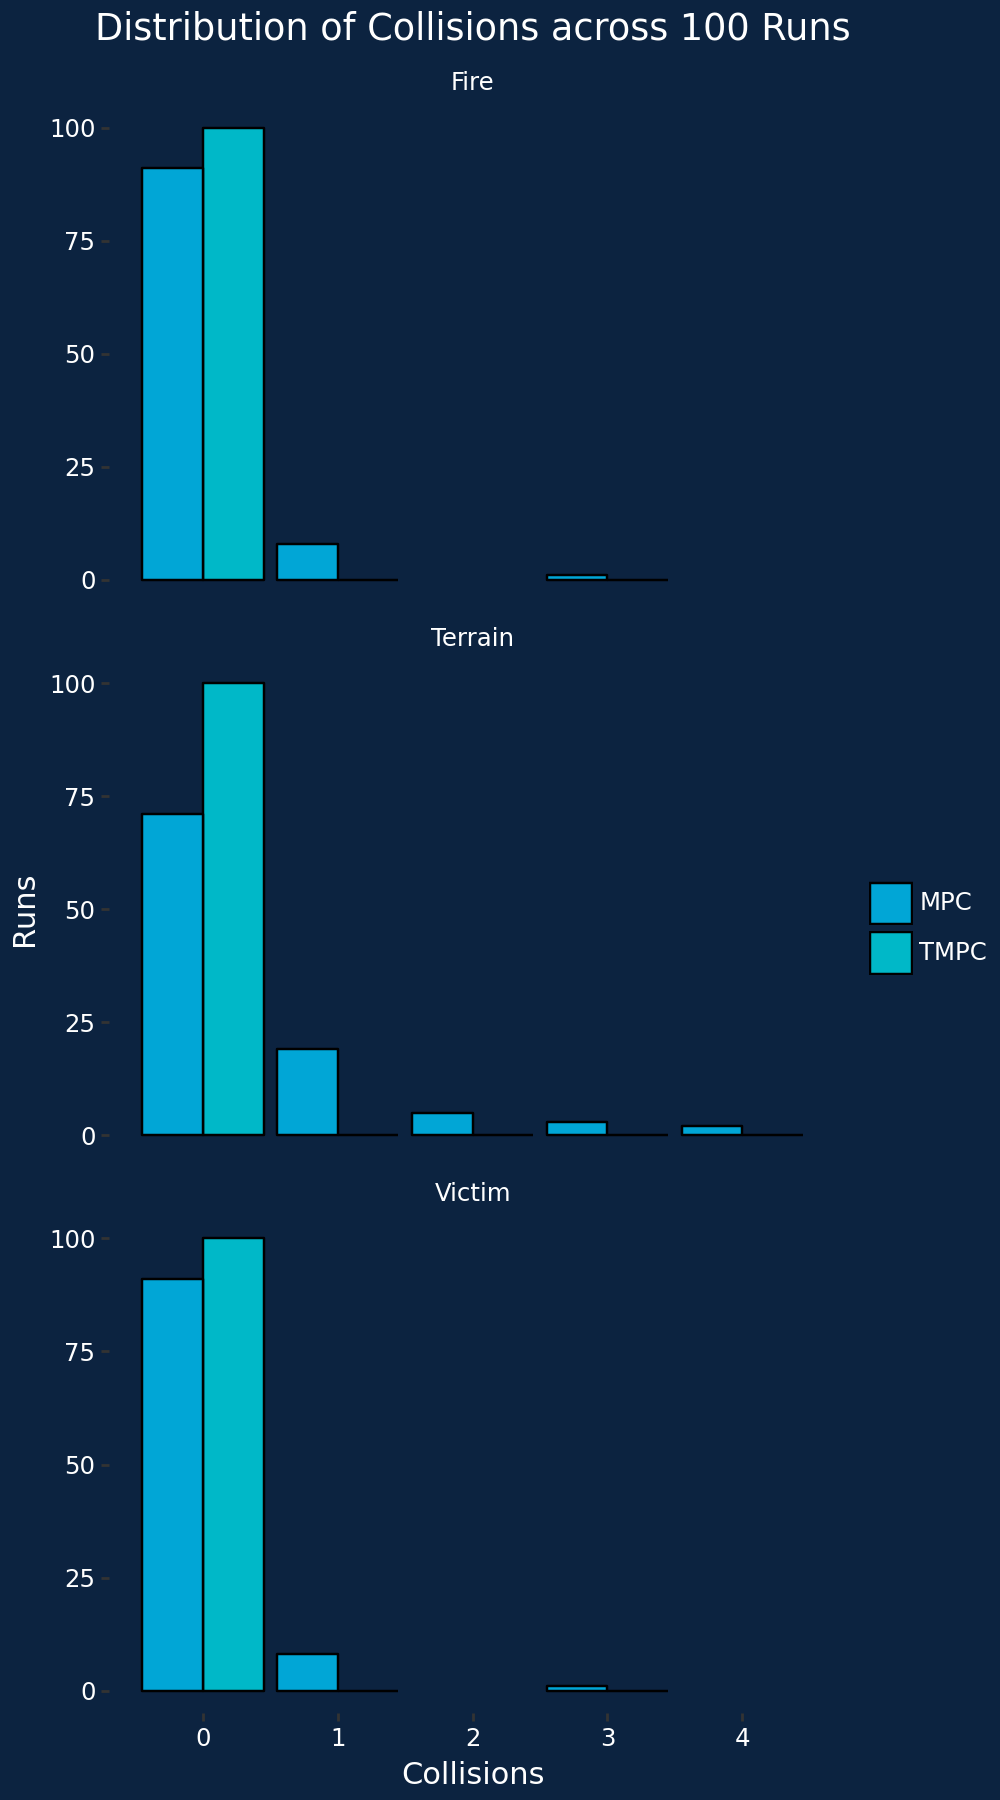

In [192]:
(
    ggplot(collisions, aes(x='collisions', y='count', fill='type'))
           + geom_col(position='dodge', colour='black')
           + facet_wrap('collision_type', nrow=3)
           + labs(x='Collisions', y='Runs', title='Distribution of Collisions across 100 Runs', fill='')
           + scale_fill_manual(values=['#01A6D6', '#00B8C8'])
           + theme_poster((5, 9))
)

# Run Time

### Data Handling

In [ ]:
runtimes = data[['outcome', 'duration', 'type']]
runtimes.columns = ['Outcome', 'Duration', 'type']

success = runtimes[runtimes['Outcome']=='SUCCESS'].groupby(['type', 'Outcome']).count().reset_index()
success['Duration'] /= 100

,Outcome,Duration,type
0,SUCCESS,104,MPC
1,SUCCESS,138,MPC
2,SUCCESS,170,MPC
3,SUCCESS,164,MPC
4,SUCCESS,212,MPC
...,...,...,...
195,SUCCESS,174,TMPC
196,TIMEOUT,300,TMPC
197,SUCCESS,252,TMPC
198,SUCCESS,121,TMPC


### Plotting

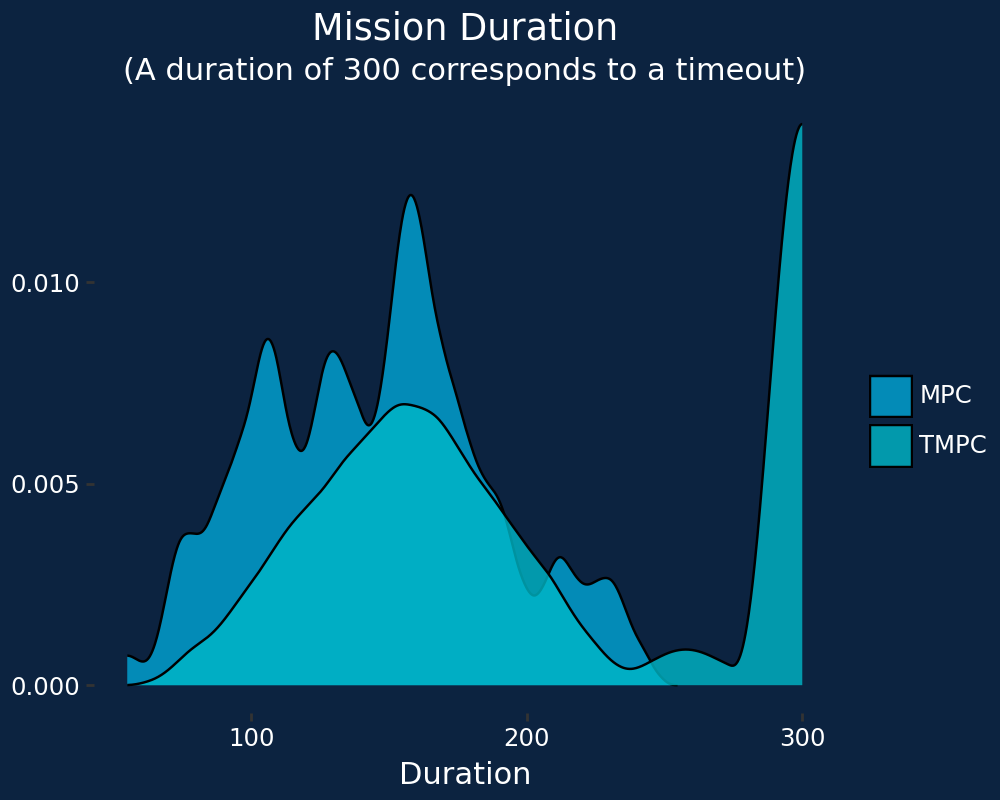

In [184]:
(
    ggplot(runtimes, aes(x='Duration', fill='type'))
           + geom_density(kernel='triw', position='identity', alpha=0.8)
           + labs(x='Duration', y='', title='Mission Duration', subtitle='(A duration of 300 corresponds to a timeout)', fill='')
           + scale_fill_manual(values=['#01A6D6', '#00B8C8'])
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'), plot_subtitle=element_text(ha='center'))
)

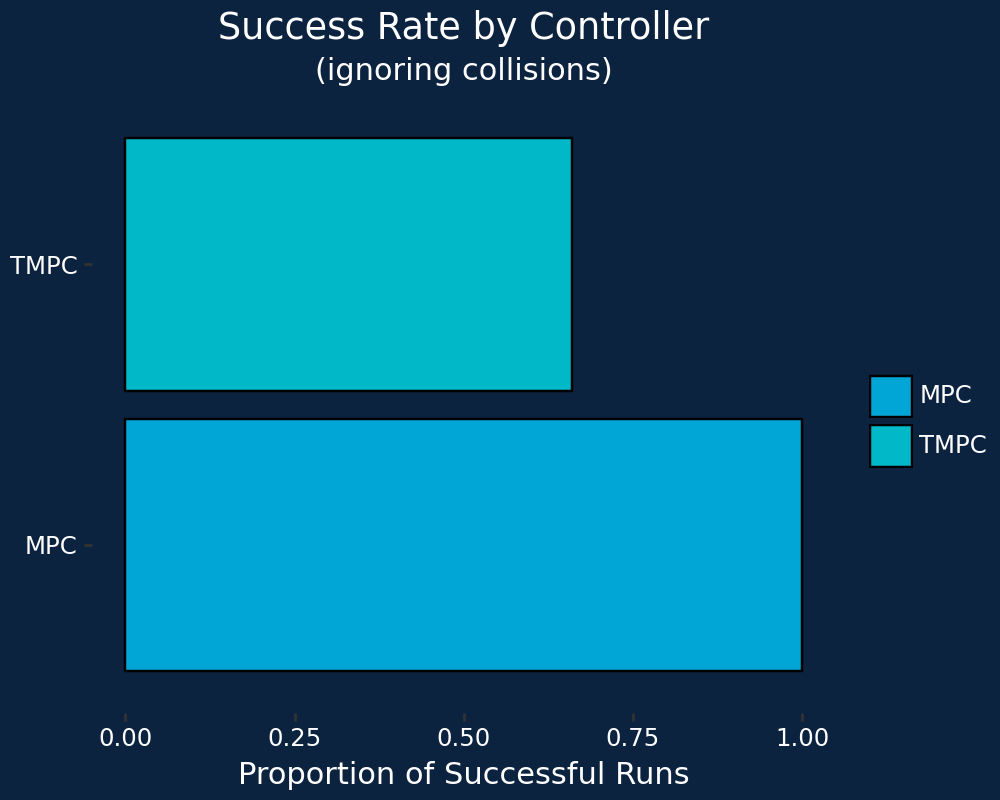

In [191]:
(
    ggplot(success, aes(x='type', y='Duration', fill='type'))
           + geom_col(colour='black')
           + coord_flip()
           + labs(x='', y='Proportion of Successful Runs', title='Success Rate by Controller', subtitle='(ignoring collisions)', fill='')
           + scale_fill_manual(values=['#01A6D6', '#00B8C8'])
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'), plot_subtitle=element_text(ha='center'))
)